Samajhna pehle: Aaj tak ke saare numbers ek imandaar report mein aayenge. Kal tumne final model CV se chuna aur commit kar diya. Aaj wahi model test set par ek baar score hoga, aur uski uncertainty (confidence intervals) bhi dikhegi.

Aaj ke rules:

1. Model badalna mana hai. Faisla kal ki final_model_choice_day84.md mein ho chuka hai. Test par doosra model behtar nikle to bhi switch nahi karna, use report mein observation ki tarah likhna hai.
2. Threshold CV ke out-of-fold predictions se chuna jayega, test se nahi.
3. Test par final model ka score wala cell ek hi baar chalana hai. Kuch galat lage to cell ko bina dekhe dobara chalane ke bajaye mujhse poochho.
4. Baaki models ka test score sirf reference ke liye hai, selection ke liye nahi.

1. Setup aur pre-registration verify

In [3]:
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../../')))
import warnings; warnings.filterwarnings('ignore')
import re, json, joblib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score, f1_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from src.models.search_spaces import get_search_spaces
from src.models.bootstrap import bootstrap_metric, ci, precision_at_frac, recall_at_frac

X_tr = pd.read_csv('../../data/processed/X_train_v2.csv').astype(float)
X_te = pd.read_csv('../../data/processed/X_test_v2.csv').astype(float)
y_tr = pd.read_csv('../../data/processed/y_train.csv').squeeze().values
y_te = pd.read_csv('../../data/processed/y_test.csv').squeeze().values
assert len(X_tr) == len(y_tr) and len(X_te) == len(y_te)
assert list(X_tr.columns) == list(X_te.columns)
print("Train:", X_tr.shape, "| Test:", X_te.shape, "| test churners:", int(y_te.sum()))

txt = open('../../reports/final_model_choice_day84.md').read()
final_name = re.search(r'- Model: (.+)', txt).group(1).strip()
final_params = json.loads(re.search(r'- Params: (.+)', txt).group(1))
print("Pre-registered:", final_name, final_params)
print(subprocess.run(['git', 'log', '--format=%h %ad %s', '--date=iso', '--', '../../reports/final_model_choice_day84.md'],
                     capture_output=True, text=True).stdout)

Train: (4226, 21) | Test: (1057, 21) | test churners: 598
Pre-registered: XGBoost {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 150}



Git log mein final_model_choice_day84.md ka commit dikhna chahiye. Agar nahi dikhta, to kal wala commit skip hua tha. Ab commit mat banao, balki yeh baat README mein honestly se likho.

2. Final model ko pre-registered parameters se dobara banao

In [4]:
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
spaces = get_search_spaces(pos_weight)
final_est = clone(spaces[final_name][0]).set_params(**final_params)
if 'n_jobs' in final_est.get_params():
    final_est.set_params(n_jobs=-1)

Kal best_estimator_ rank-1 params se saved tha, jabki pre-registered model 1-SE (simple) params se bana tha. Isliye final model yahan dobara banaya jaa raha hai.

3. Threshold: CV ke out-of-fold predictions + business cost

Net-value threshold: 0.07 | F1-best threshold: 0.32


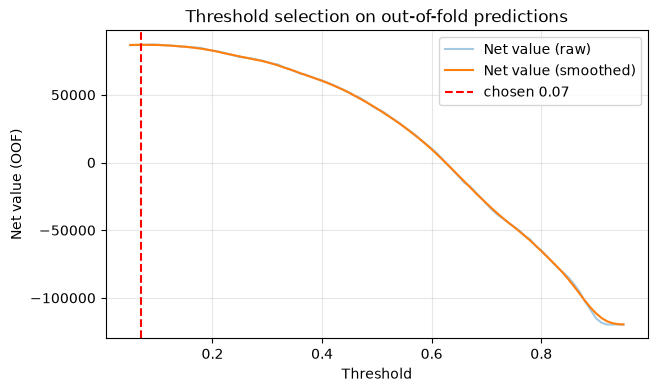

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(final_est, X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]

COST_FN, COST_FP, BENEFIT_TP = 50, 5, 40        # Day 71 ke ASSUMPTIONS, apne hisaab se badlo

def net_value(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return tp * BENEFIT_TP - fp * COST_FP - fn * COST_FN

ts = np.round(np.linspace(0.05, 0.95, 91), 2)
net = np.array([net_value(y_tr, (oof >= t).astype(int)) for t in ts])
net_smooth = pd.Series(net).rolling(7, center=True, min_periods=1).mean().values   # spiky argmax se bachne ke liye
THRESHOLD = float(ts[net_smooth.argmax()])

f1s = [f1_score(y_tr, (oof >= t).astype(int), zero_division=0) for t in ts]
print(f"Net-value threshold: {THRESHOLD:.2f} | F1-best threshold: {ts[int(np.argmax(f1s))]:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(ts, net, alpha=0.4, label='Net value (raw)')
plt.plot(ts, net_smooth, label='Net value (smoothed)')
plt.axvline(THRESHOLD, color='red', linestyle='--', label=f'chosen {THRESHOLD:.2f}')
plt.xlabel('Threshold'); plt.ylabel('Net value (OOF)')
plt.title('Threshold selection on out-of-fold predictions')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

Net-value curve agar ek chhoti si cheekh (spike) ki jagah chaura plateau dikhaye, to threshold stable hai. Dhyan rakho ki class_weight ya scale_pos_weight se probabilities inflate hoti hain. Out-of-fold probabilities mein bhi wahi inflation hai, isliye is par chuna threshold test par bhi lagega.

4. Test par final model: ek hi baar (is cell ko dobara mat chalana)

In [6]:
final_est.fit(X_tr, y_tr)
p_te = final_est.predict_proba(X_te)[:, 1]
pred_te = (p_te >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_te, pred_te, labels=[0, 1]).ravel()
print(f"TN={tn} FP={fp} FN={fn} TP={tp} | flagged {pred_te.mean():.1%} (OOF mein {(oof >= THRESHOLD).mean():.1%})")

TN=37 FP=422 FN=1 TP=597 | flagged 96.4% (OOF mein 97.1%)


Flagged share test aur OOF mein lagbhag same hona chahiye. Bahut alag ho, to model ya split mein kuch gadbad hai.

5. Sab models ka test score (sirf reference ke liye)

In [11]:
names = {'LogReg': 'logreg', 'Tree': 'tree', 'RandomForest': 'randomforest', 'XGBoost': 'xgboost'}
cands = {n: joblib.load(f'models/tuned_{f}_v2.joblib') for n, f in names.items()}
cands[final_name] = final_est                                              # pre-registered version
cands['Baseline (prior)'] = DummyClassifier(strategy='prior').fit(X_tr, y_tr)

test_scores = {n: m.predict_proba(X_te)[:, 1] for n, m in cands.items()}
test_scores['LogReg v1 (Month 4)'] = joblib.load('../model/logreg_pipeline.joblib').predict_proba(
    pd.read_csv('../../data/processed/X_test.csv'))[:, 1]

b_auc = bootstrap_metric(y_te, test_scores, roc_auc_score)
b_ap = bootstrap_metric(y_te, test_scores, average_precision_score)

rows = []
for n, s in test_scores.items():
    rows.append({'model': n,
                 'test_auc': roc_auc_score(y_te, s), 'auc_lo': ci(b_auc[n])[0], 'auc_hi': ci(b_auc[n])[1],
                 'test_ap': average_precision_score(y_te, s), 'ap_lo': ci(b_ap[n])[0], 'ap_hi': ci(b_ap[n])[1]})
tbl = pd.DataFrame(rows).set_index('model')
print(tbl.round(3))
print(f"\nPre-registered model: {final_name} | Best test AUC: {tbl['test_auc'].idxmax()}")

                     test_auc  auc_lo  auc_hi  test_ap  ap_lo  ap_hi
model                                                               
LogReg                  0.811   0.783   0.836    0.837  0.806  0.866
Tree                    0.802   0.774   0.829    0.801  0.766  0.835
RandomForest            0.818   0.792   0.843    0.839  0.806  0.869
XGBoost                 0.818   0.791   0.843    0.838  0.804  0.868
Baseline (prior)        0.500   0.500   0.500    0.566  0.535  0.597
LogReg v1 (Month 4)     0.809   0.782   0.835    0.833  0.801  0.863

Pre-registered model: XGBoost | Best test AUC: RandomForest


Kaise padho:

- Jinke confidence intervals aapas mein overlap karte hain, unmein “ek jeeta” mat bolo.
- Agar koi doosra model test par achha dikhe, to wo selection ka nateeja nahi hai. Wo 5-6 models mein se ek ka lucky number ho sakta hai (jitne zyada models dekhoge, utna zyada chance ki koi ek achha dikhe).
- LogReg v1 (Month 4) wali row batati hai ki Month 5 ke features aur models ne Month 4 se kitna kuch sudhara.

6. Paired difference (kya final model asli mein behtar hai?)

In [12]:
ref = 'LogReg' if final_name != 'LogReg' else 'Tree'
for other in [ref, 'LogReg v1 (Month 4)', 'Baseline (prior)']:
    d = b_auc[final_name] - b_auc[other]
    lo, hi = ci(d)
    verdict = "clear" if (lo > 0 or hi < 0) else "0 ko cover karta hai, noise ke andar"
    print(f"AUC({final_name}) - AUC({other}): {d.mean():+.4f}  95% CI ({lo:+.4f}, {hi:+.4f})  -> {verdict}")

AUC(XGBoost) - AUC(LogReg): +0.0071  95% CI (-0.0000, +0.0142)  -> 0 ko cover karta hai, noise ke andar
AUC(XGBoost) - AUC(LogReg v1 (Month 4)): +0.0082  95% CI (+0.0003, +0.0167)  -> clear
AUC(XGBoost) - AUC(Baseline (prior)): +0.3178  95% CI (+0.2913, +0.3432)  -> clear


Yeh sabse imandaar jaanch hai. Resamples sab models ke liye same hain, isliye fark ka interval chhota aur meaningful hota hai.

7. Threshold par metrics aur confidence intervals

In [13]:
metrics_at_t = {
    'precision': lambda yy, ss: precision_score(yy, (ss >= THRESHOLD).astype(int), zero_division=0),
    'recall':    lambda yy, ss: recall_score(yy, (ss >= THRESHOLD).astype(int), zero_division=0),
    'F1':        lambda yy, ss: f1_score(yy, (ss >= THRESHOLD).astype(int), zero_division=0),
}
out = {}
for k, fn_ in metrics_at_t.items():
    b = bootstrap_metric(y_te, {'m': p_te}, fn_)['m']
    out[k] = {'value': fn_(y_te, p_te), 'lo': ci(b)[0], 'hi': ci(b)[1]}
print(pd.DataFrame(out).T.round(3))
print("Naive 'hamesha majority' accuracy:", round(1 - y_te.mean(), 3), "| Model accuracy:", round((pred_te == y_te).mean(), 3))

           value     lo     hi
precision  0.586  0.555  0.616
recall     0.998  0.995  1.000
F1         0.738  0.713  0.762
Naive 'hamesha majority' accuracy: 0.434 | Model accuracy: 0.6


8. Business view: top-K targeting aur net value

In [14]:
prev = y_te.mean()
rows = []
for frac in [0.05, 0.10, 0.20, 0.30]:
    pf = lambda yy, ss, f=frac: precision_at_frac(yy, ss, f)
    rf = lambda yy, ss, f=frac: recall_at_frac(yy, ss, f)
    bp = bootstrap_metric(y_te, {'m': p_te}, pf)['m']
    rows.append({'budget (top %)': int(frac * 100),
                 'precision@k': pf(y_te, p_te), 'p_lo': ci(bp)[0], 'p_hi': ci(bp)[1],
                 'recall@k': rf(y_te, p_te), 'lift': pf(y_te, p_te) / prev})
print(pd.DataFrame(rows).round(3))

P, N = int(y_te.sum()), int((y_te == 0).sum())
print("\nNet value (assumed costs):")
print("  Model @ threshold      :", net_value(y_te, pred_te))
print("  Sabko contact karo     :", P * BENEFIT_TP - N * COST_FP)
print("  Kisi ko contact na karo:", -P * COST_FN)

   budget (top %)  precision@k   p_lo   p_hi  recall@k   lift
0               5        0.923  0.846  0.981     0.080  1.632
1              10        0.924  0.857  0.971     0.162  1.633
2              20        0.891  0.844  0.934     0.314  1.575
3              30        0.852  0.811  0.896     0.452  1.505

Net value (assumed costs):
  Model @ threshold      : 21720
  Sabko contact karo     : 21625
  Kisi ko contact na karo: -29900


Yeh sawal ka asli jawab hai: “Retention budget ko model se kitna faida hota hai, bina model ke kitna?” Assumed costs ko apne hisaab se update karo, aur README mein likhna ki yeh assumptions hain.

9. Stability aur red-flag checks

In [16]:
nested = pd.read_csv('../../reports/nested_cv_day84.csv', index_col=0)
print(nested.round(3))
print(f"\nNested CV AUC (Day 84, honest) : {nested.loc[final_name, 'nested_auc (honest)']:.3f}")
print(f"OOF AUC (threshold wale preds)   : {roc_auc_score(y_tr, oof):.3f}")
print(f"Test AUC                         : {roc_auc_score(y_te, p_te):.3f}")

if roc_auc_score(y_te, p_te) > 0.95:
    print("SHAK: itna ooncha AUC leakage ka signal ho sakta hai, Day 82 ka invariance test dobara chalao")

              search_best_auc (optimistic)  nested_auc (honest)  nested_std  \
LogReg                               0.796                0.796       0.014   
Tree                                 0.785                0.778       0.016   
RandomForest                         0.799                0.802       0.014   
XGBoost                              0.802                0.803       0.016   

              optimism  
LogReg          -0.000  
Tree             0.008  
RandomForest    -0.003  
XGBoost         -0.001  

Nested CV AUC (Day 84, honest) : 0.803
OOF AUC (threshold wale preds)   : 0.799
Test AUC                         : 0.818


Teeno numbers paas-paas hone chahiye. Test AUC nested se kaafi kam ho (jaise 0.05+), to ruko aur wajah dhoondo (split, leakage, chhota test set). Phir bhi model ya threshold test dekh kar mat badlo, sirf finding likho.

Region-wise check (kya model kisi group par kamzor hai?):

In [17]:
region = np.where(X_te['Region_UK'] == 1, 'UK', np.where(X_te['Region_Rest of World'] == 1, 'Rest of World', 'Rest of Europe'))
for r in ['UK', 'Rest of Europe', 'Rest of World']:
    m = region == r
    ok = m.sum() > 0 and len(np.unique(y_te[m])) == 2
    print(f"{r}: n={m.sum()}, churners={int(y_te[m].sum())}, AUC={roc_auc_score(y_te[m], p_te[m]):.3f}" if ok
          else f"{r}: n={m.sum()}, AUC define nahi (chhota ya ek class)")

UK: n=972, churners=552, AUC=0.814
Rest of Europe: n=74, churners=37, AUC=0.861
Rest of World: n=11, churners=9, AUC=0.889


Chhote groups ka AUC bharosemand nahi hota. Wahi caveat likho.

10. Charts (ROC, PR, aur CI wala forest plot)

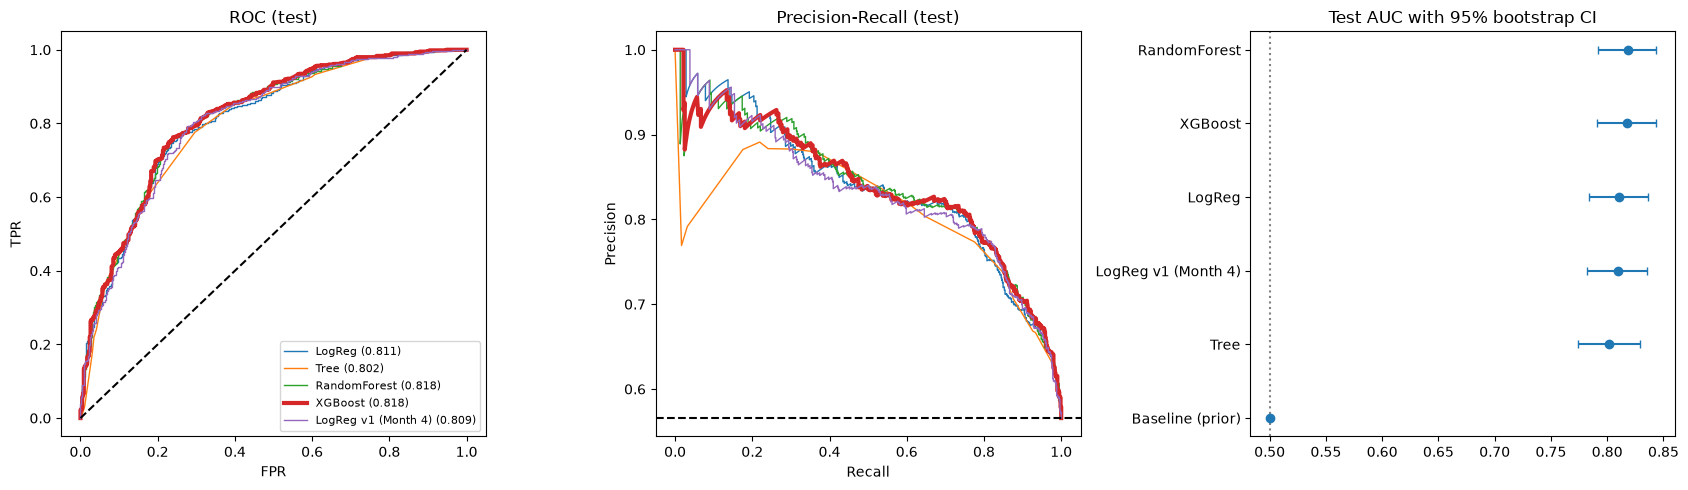

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for n, s in test_scores.items():
    if n == 'Baseline (prior)':
        continue
    fpr, tpr, _ = roc_curve(y_te, s)
    pr, rc, _ = precision_recall_curve(y_te, s)
    lw = 3 if n == final_name else 1
    axes[0].plot(fpr, tpr, linewidth=lw, label=f"{n} ({roc_auc_score(y_te, s):.3f})")
    axes[1].plot(rc, pr, linewidth=lw, label=n)
axes[0].plot([0, 1], [0, 1], 'k--'); axes[0].set_title('ROC (test)'); axes[0].legend(fontsize=8)
axes[1].axhline(y_te.mean(), color='k', linestyle='--'); axes[1].set_title('Precision-Recall (test)')
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')

o = tbl.sort_values('test_auc')
axes[2].errorbar(o['test_auc'], range(len(o)),
                 xerr=[o['test_auc'] - o['auc_lo'], o['auc_hi'] - o['test_auc']], fmt='o', capsize=3)
axes[2].set_yticks(range(len(o))); axes[2].set_yticklabels(o.index)
axes[2].axvline(0.5, color='gray', linestyle=':'); axes[2].set_title('Test AUC with 95% bootstrap CI')
plt.tight_layout()
plt.savefig('../../reports/final_comparison_day85.png', dpi=150)
plt.show()

Forest plot mein jin models ke intervals overlap karte hain, wahi “barabar” hain.

11. Report aur model card save karo

In [19]:
cm_txt = f"TN={tn}, FP={fp}, FN={fn}, TP={tp}"
with open('../../reports/model_comparison_report.md', 'w') as f:
    f.write(f"""# Model Comparison Report (Day 85)

**Final model (pre-registered on Day 84, chosen on CV only):** {final_name}
**Threshold:** {THRESHOLD:.2f}, chosen from out-of-fold predictions using assumed costs (FN={COST_FN}, FP={COST_FP}, TP benefit={BENEFIT_TP}).
**Test set:** n={len(y_te)}, churners={int(y_te.sum())}. Final model scored once.

## Test performance (all models, reference only; selection was not based on this table)
{tbl.round(3).to_markdown()}

## Final model at chosen threshold
{pd.DataFrame(out).T.round(3).to_markdown()}

Confusion matrix: {cm_txt}

## Caveats
- Test set has few churners, so intervals are wide. Differences inside the intervals are not real differences.
- Probabilities are inflated by class weighting; the model is meant for ranking, not for calibrated risk percentages.
- Costs are assumptions, not measured business numbers.
""")

card = {'model': final_name, 'params': final_params, 'threshold': THRESHOLD,
        'features': list(X_tr.columns), 'test_auc': float(roc_auc_score(y_te, p_te)),
        'assumed_costs': {'FN': COST_FN, 'FP': COST_FP, 'TP_benefit': BENEFIT_TP}}
json.dump(card, open('../../reports/final_model_card.json', 'w'), indent=2)
joblib.dump(final_est, '../model/final_model.joblib')

['../model/final_model.joblib']

features list ka order hi Streamlit app ke liye zaroori hoga (Day 88): user ka input isi column order mein model ko jaana chahiye. final_model.joblib .gitignore mein rahegi, aur wo theek hai. Model card JSON chhoti hai aur Git mein jaayegi.

12. README ke liye note (apne numbers se bharo):

## Final Model and Evaluation
Final model: [name], chosen on cross-validation only and recorded in `reports/final_model_choice_day84.md` before the test set was scored.
Test ROC-AUC [X] (95% CI [X]-[X]); PR-AUC [X] vs churn rate [X].
Versus Month 4 LogReg: ROC-AUC [X] -> [X] (difference CI [X] to [X], [clear / within noise]).
Targeting the top 10% highest-risk customers captures [X]% of churners at [X]x the precision of random targeting.
Limitations: [X] churners in the test set; probabilities are for ranking, not calibrated; costs are assumed.

Agar Month 5 ke models ne Month 4 se asli faida nahi diya, to yahi likho. Interviewer ko imandaari achhi lagti hai.

practice questions:

1. COST_FP ko 5 se 20 aur 40 karke step 3 dobara chalao, aur dekho ki threshold kis taraf khisakta hai. Ye sirf CV par karna, test dekh kar nahi.
2. Apne shabdon mein likho: forest plot mein jab do models ke CI overlap karte hain, to hum kya nahi keh sakte? Ek manager ko ye kaise samjhaoge?
3. Report mein “Caveats” ke 3 points apne project ke hisaab se likho (jaise test churners ki ginti, pichla data 2009-2011, chuni hui assumptions).